# Brain-Inspired Computational Intelligence via Predictive Coding

This notebook implements a simplified Predictive Coding network based on the core computational principles of the paper and compares Predictive Coding with conventional Backpropagation.

* **Backpropagation (BP):** Standard global gradient descent using a **1-8-1 neural network** with one input layer, one hidden layer of 8 neurons, and one output layer.

* **Predictive Coding (PC):** Local prediction-error minimization using the same **1-8-1 architecture**, followed by an extended **1-8-8-1 deeper predictive-coding network**.

The main objectives are:

* Train a **1-8-1 neural network** using Backpropagation.
* Train a **1-8-1 Predictive Coding network** using local prediction errors.
* Demonstrate iterative free-energy minimization during inference.
* Compare the final prediction errors of PC and BP.
* Demonstrate PC's key properties of **free-energy minimization and local learning**.
* Extend Predictive Coding to a **deeper 1-8-8-1 hierarchical network**.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)  # reproducibility

## 1. Data
Target function: Y = sin(3X) + 0.1X

In [ ]:
X = np.linspace(-1, 1, 100).reshape(-1, 1)   # 100 inputs in [-1, 1]
Y = np.sin(3 * X) + 0.1 * X                  # nonlinear target

## 2. Network setup
Architecture: 1 -> 8 -> 1, tanh activation.

In [ ]:
input_size, hidden_size, output_size = 1, 8, 1

def tanh(x):
    return np.tanh(x)

def tanh_derivative(x):
    return 1 - np.tanh(x) ** 2

## 3. Backpropagation baseline

In [ ]:
W1_bp = np.random.randn(hidden_size, input_size) * 0.5
b1_bp = np.zeros((hidden_size, 1))
W2_bp = np.random.randn(output_size, hidden_size) * 0.5
b2_bp = np.zeros((output_size, 1))

lr_bp, epochs = 0.05, 300
bp_loss_history = []

for epoch in range(epochs):
    Z1 = W1_bp @ X.T + b1_bp          # hidden pre-activation
    H = tanh(Z1)                      # hidden activation
    Y_pred = W2_bp @ H + b2_bp        # output prediction

    error = Y_pred - Y.T
    bp_loss_history.append(np.mean(error ** 2))

    dY = 2 * error / X.shape[0]       # output gradient
    dW2 = dY @ H.T
    db2 = np.sum(dY, axis=1, keepdims=True)

    dH = W2_bp.T @ dY                 # backprop to hidden layer
    dZ1 = dH * tanh_derivative(Z1)
    dW1 = dZ1 @ X
    db1 = np.sum(dZ1, axis=1, keepdims=True)

    W2_bp -= lr_bp * dW2; b2_bp -= lr_bp * db2
    W1_bp -= lr_bp * dW1; b1_bp -= lr_bp * db1

print("Final BP loss:", bp_loss_history[-1])

Final BP loss: 0.08114541989532581


## 4. Predictive Coding model
PC has two steps per sample: **inference** (relax hidden state to reduce free energy)
then **learning** (update weights using local errors only).

Free energy: F = 1/2 (||hidden error||^2 + ||output error||^2)

In [ ]:
W1_pc = np.random.randn(hidden_size, input_size) * 0.5
b1_pc = np.zeros((hidden_size, 1))
W2_pc = np.random.randn(output_size, hidden_size) * 0.5
b2_pc = np.zeros((output_size, 1))

lr_pc, inference_lr = 0.01, 0.05
inference_steps, pc_epochs = 20, 300

def pc_inference(x, target, W1, b1, W2, b2, steps, lr):
    # Relax hidden state to minimize free energy (Eq. 5)
    hidden = tanh(W1 @ x + b1)
    energy_history = []
    for _ in range(steps):
        predicted_hidden = tanh(W1 @ x + b1)
        predicted_output = W2 @ hidden + b2
        hidden_error = hidden - predicted_hidden
        output_error = target - predicted_output

        free_energy = 0.5 * (np.sum(hidden_error ** 2) + np.sum(output_error ** 2))
        energy_history.append(free_energy)

        grad = hidden_error - W2.T @ output_error   # gradient of F wrt hidden state
        hidden -= lr * grad
    return hidden, energy_history

def pc_weight_update(x, target, hidden, W1, b1, W2, b2, lr):
    # Update weights using only local errors (Eq. 6)
    z1 = W1 @ x + b1
    predicted_hidden = tanh(z1)
    predicted_output = W2 @ hidden + b2

    hidden_error = hidden - predicted_hidden
    output_error = target - predicted_output
    d_act = tanh_derivative(z1)

    W1 += lr * (hidden_error * d_act) @ x.T
    b1 += lr * (hidden_error * d_act)
    W2 += lr * output_error @ hidden.T
    b2 += lr * output_error
    return W1, b1, W2, b2

Train PC: inference then learning, per sample, per epoch.

In [ ]:
pc_free_energy_history, pc_output_error_history = [], []

for epoch in range(pc_epochs):
    total_fe, total_err = 0, 0
    for i in range(len(X)):
        x, target = X[i].reshape(-1, 1), Y[i].reshape(-1, 1)

        hidden, energy_history = pc_inference(
            x, target, W1_pc, b1_pc, W2_pc, b2_pc, inference_steps, inference_lr)
        W1_pc, b1_pc, W2_pc, b2_pc = pc_weight_update(
            x, target, hidden, W1_pc, b1_pc, W2_pc, b2_pc, lr_pc)

        total_fe += energy_history[-1]
        prediction = W2_pc @ hidden + b2_pc
        total_err += np.mean((target - prediction) ** 2)

    pc_free_energy_history.append(total_fe / len(X))
    pc_output_error_history.append(total_err / len(X))

    if epoch % 25 == 0 or epoch == pc_epochs - 1:
        print(f"PC Epoch {epoch:3d} | Free Energy = {pc_free_energy_history[-1]:.6f} "
              f"| Output Error = {pc_output_error_history[-1]:.6f}")

PC Epoch   0 | Free Energy = 0.153579 | Output Error = 0.135407


PC Epoch  25 | Free Energy = 0.015227 | Output Error = 0.006522


PC Epoch  50 | Free Energy = 0.011959 | Output Error = 0.004118


PC Epoch  75 | Free Energy = 0.009749 | Output Error = 0.002889


PC Epoch 100 | Free Energy = 0.008063 | Output Error = 0.002135


...

PC Epoch 200 | Free Energy = 0.003768 | Output Error = 0.000759


PC Epoch 225 | Free Energy = 0.003104 | Output Error = 0.000598


PC Epoch 250 | Free Energy = 0.002563 | Output Error = 0.000476


PC Epoch 275 | Free Energy = 0.002124 | Output Error = 0.000381


PC Epoch 299 | Free Energy = 0.001782 | Output Error = 0.000311


## 5. Free-energy minimization during inference
One sample, weights fixed, hidden state relaxed over 30 steps.

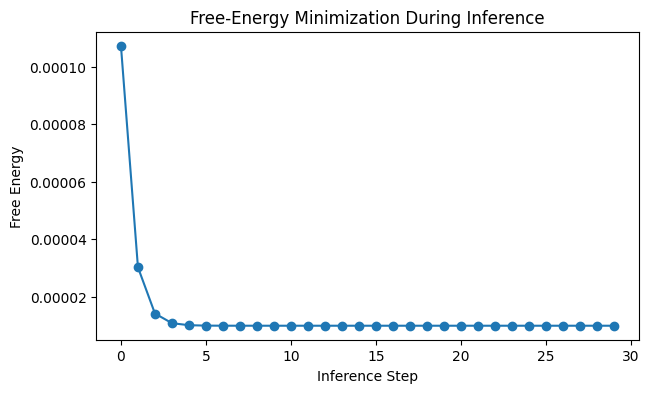

In [ ]:
x, target = X[50].reshape(-1, 1), Y[50].reshape(-1, 1)
_, energy_history = pc_inference(x, target, W1_pc, b1_pc, W2_pc, b2_pc, steps=30, lr=inference_lr)

plt.figure(figsize=(7, 4))
plt.plot(energy_history, marker="o")
plt.xlabel("Inference Step"); plt.ylabel("Free Energy")
plt.title("Free-Energy Minimization During Inference")
plt.show()

## 6. PC vs BP: learning curves

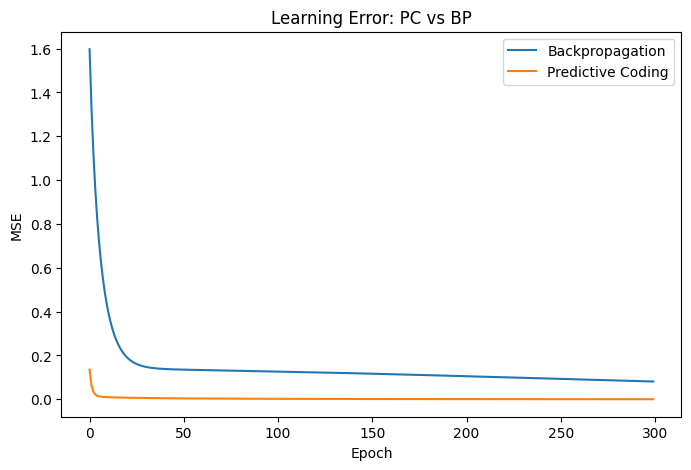

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(bp_loss_history, label="Backpropagation")
plt.plot(pc_output_error_history, label="Predictive Coding")
plt.xlabel("Epoch"); plt.ylabel("MSE")
plt.title("Learning Error: PC vs BP")
plt.legend(); plt.show()

## 7. Final predictions and MSE

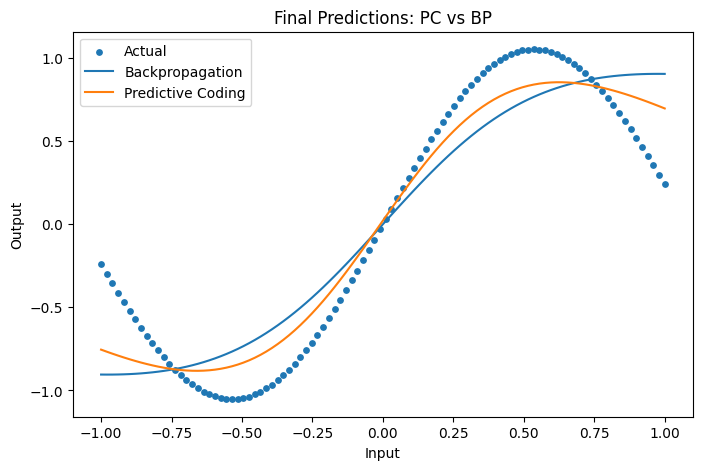

BP MSE: 0.080905
PC MSE: 0.038589
PC error reduction vs BP: 52.30%
Final PC free energy: 0.001782


In [ ]:
# BP predictions
H_bp = tanh(W1_bp @ X.T + b1_bp)
Y_bp = (W2_bp @ H_bp + b2_bp).flatten()

# PC predictions (target not used at prediction time)
Y_pc = np.array([
    (W2_pc @ tanh(W1_pc @ X[i].reshape(-1, 1) + b1_pc) + b2_pc).item()
    for i in range(len(X))
])

plt.figure(figsize=(8, 5))
plt.scatter(X, Y, s=15, label="Actual")
plt.plot(X, Y_bp, label="Backpropagation")
plt.plot(X, Y_pc, label="Predictive Coding")
plt.xlabel("Input"); plt.ylabel("Output")
plt.title("Final Predictions: PC vs BP")
plt.legend(); plt.show()

bp_mse = np.mean((Y.flatten() - Y_bp) ** 2)
pc_mse = np.mean((Y.flatten() - Y_pc) ** 2)
improvement = (bp_mse - pc_mse) / bp_mse * 100

print(f"BP MSE: {bp_mse:.6f}")
print(f"PC MSE: {pc_mse:.6f}")
print(f"PC error reduction vs BP: {improvement:.2f}%")
print(f"Final PC free energy: {pc_free_energy_history[-1]:.6f}")

8. Extending PC to a deeper network
Paper: PC rules are local, so they generalize unchanged to any depth.
Here we test a 1-8-8-1 network (two hidden layers).

In [ ]:
np.random.seed(0)
layer_sizes = [1, 8, 8, 1]
n_layers = len(layer_sizes) - 1

Ws_deep = [np.random.randn(layer_sizes[i+1], layer_sizes[i]) * 0.5 for i in range(n_layers)]
bs_deep = [np.zeros((layer_sizes[i+1], 1)) for i in range(n_layers)]

deep_lr_pc, deep_inference_lr = 0.01, 0.05
deep_inference_steps, deep_epochs = 20, 300

def deep_pc_inference(x, target, Ws, bs, steps, lr):
    # Relax every hidden layer's value node (generalizes pc_inference)
    activations = [x]
    for W, b in zip(Ws, bs):
        activations.append(tanh(W @ activations[-1] + b))

    energy_history = []
    for _ in range(steps):
        preds = [x]
        for W, b in zip(Ws, bs):
            preds.append(tanh(W @ preds[-1] + b))

        errors = [activations[l] - preds[l] for l in range(1, len(activations) - 1)]
        errors.append(target - (Ws[-1] @ activations[-2] + bs[-1]))  # output error

        energy_history.append(0.5 * sum(np.sum(e ** 2) for e in errors))

        for l in range(1, len(activations) - 1):
            z_l = Ws[l-1] @ activations[l-1] + bs[l-1]
            top_down = Ws[l].T @ errors[l]
            grad = errors[l-1] - tanh_derivative(z_l) * top_down
            activations[l] -= lr * grad
    return activations, energy_history

def deep_pc_weight_update(x, target, activations, Ws, bs, lr):
    # Local weight update per layer (generalizes pc_weight_update)
    for l in range(len(Ws) - 1):
        z_l = Ws[l] @ activations[l] + bs[l]
        local_error = activations[l+1] - tanh(z_l)
        d_act = tanh_derivative(z_l)
        Ws[l] += lr * (local_error * d_act) @ activations[l].T
        bs[l] += lr * (local_error * d_act)

    output_error = target - (Ws[-1] @ activations[-2] + bs[-1])
    Ws[-1] += lr * output_error @ activations[-2].T
    bs[-1] += lr * output_error
    return Ws, bs

deep_output_error_history = []
for epoch in range(deep_epochs):
    total_err = 0
    for i in range(len(X)):
        x, target = X[i].reshape(-1, 1), Y[i].reshape(-1, 1)
        activations, _ = deep_pc_inference(x, target, Ws_deep, bs_deep, deep_inference_steps, deep_inference_lr)
        Ws_deep, bs_deep = deep_pc_weight_update(x, target, activations, Ws_deep, bs_deep, deep_lr_pc)
        prediction = Ws_deep[-1] @ activations[-2] + bs_deep[-1]
        total_err += np.mean((target - prediction) ** 2)

    deep_output_error_history.append(total_err / len(X))
    if epoch % 25 == 0 or epoch == deep_epochs - 1:
        print(f"Deep PC Epoch {epoch:3d} | Output Error = {deep_output_error_history[-1]:.6f}")

Deep PC Epoch   0 | Output Error = 0.062461


Deep PC Epoch  25 | Output Error = 0.017972


Deep PC Epoch  50 | Output Error = 0.006191


Deep PC Epoch  75 | Output Error = 0.003626


Deep PC Epoch 100 | Output Error = 0.002650


...

Deep PC Epoch 200 | Output Error = 0.001157


Deep PC Epoch 225 | Output Error = 0.001035


Deep PC Epoch 250 | Output Error = 0.000959


Deep PC Epoch 275 | Output Error = 0.000913


Deep PC Epoch 299 | Output Error = 0.000888


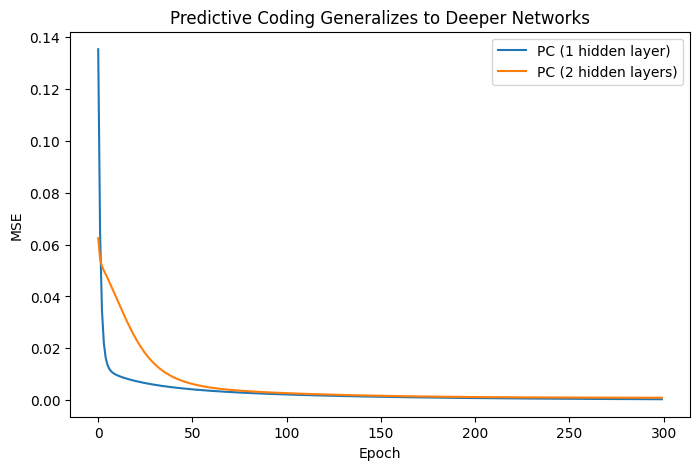

1-hidden-layer PC MSE: 0.038589
2-hidden-layer PC MSE: 0.020478


In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(pc_output_error_history, label="PC (1 hidden layer)")
plt.plot(deep_output_error_history, label="PC (2 hidden layers)")
plt.xlabel("Epoch"); plt.ylabel("MSE")
plt.title("Predictive Coding Generalizes to Deeper Networks")
plt.legend(); plt.show()

deep_pc_mse = np.mean([
    (Y[i].item() - (Ws_deep[-1] @ tanh(Ws_deep[-2] @ tanh(Ws_deep[0] @ X[i].reshape(-1,1) + bs_deep[0]) + bs_deep[-2]) + bs_deep[-1]).item()) ** 2
    for i in range(len(X))
])
print(f"1-hidden-layer PC MSE: {pc_mse:.6f}")
print(f"2-hidden-layer PC MSE: {deep_pc_mse:.6f}")

## 9. Robustness check: multiple seeds + compute cost
Here we repeat BP and PC training over 5 seeds and report mean +/- std final MSE.
We also report the extra compute PC needs per epoch (it runs an inner inference loop per sample).

In [ ]:
def train_bp(seed):
    rng = np.random.RandomState(seed)
    W1 = rng.randn(hidden_size, input_size) * 0.5
    b1 = np.zeros((hidden_size, 1))
    W2 = rng.randn(output_size, hidden_size) * 0.5
    b2 = np.zeros((output_size, 1))
    for _ in range(epochs):
        Z1 = W1 @ X.T + b1
        H = tanh(Z1)
        Y_pred = W2 @ H + b2
        error = Y_pred - Y.T
        dY = 2 * error / X.shape[0]
        dW2 = dY @ H.T; db2 = np.sum(dY, axis=1, keepdims=True)
        dH = W2.T @ dY
        dZ1 = dH * tanh_derivative(Z1)
        dW1 = dZ1 @ X; db1 = np.sum(dZ1, axis=1, keepdims=True)
        W2 -= lr_bp * dW2; b2 -= lr_bp * db2
        W1 -= lr_bp * dW1; b1 -= lr_bp * db1
    H = tanh(W1 @ X.T + b1)
    Y_bp_final = (W2 @ H + b2).flatten()
    return np.mean((Y.flatten() - Y_bp_final) ** 2)

def train_pc(seed):
    rng = np.random.RandomState(seed)
    W1 = rng.randn(hidden_size, input_size) * 0.5
    b1 = np.zeros((hidden_size, 1))
    W2 = rng.randn(output_size, hidden_size) * 0.5
    b2 = np.zeros((output_size, 1))
    for _ in range(pc_epochs):
        for i in range(len(X)):
            x, target = X[i].reshape(-1, 1), Y[i].reshape(-1, 1)
            hidden, _ = pc_inference(x, target, W1, b1, W2, b2, inference_steps, inference_lr)
            W1, b1, W2, b2 = pc_weight_update(x, target, hidden, W1, b1, W2, b2, lr_pc)
    Y_pc_final = np.array([
        (W2 @ tanh(W1 @ X[i].reshape(-1, 1) + b1) + b2).item()
        for i in range(len(X))
    ])
    return np.mean((Y.flatten() - Y_pc_final) ** 2)

seeds = [0, 1, 2, 3, 4]
bp_mses = [train_bp(s) for s in seeds]
pc_mses = [train_pc(s) for s in seeds]

print(f"BP MSE over {len(seeds)} seeds: {np.mean(bp_mses):.6f} +/- {np.std(bp_mses):.6f}")
print(f"PC MSE over {len(seeds)} seeds: {np.mean(pc_mses):.6f} +/- {np.std(pc_mses):.6f}")

# Compute cost: PC runs an inner inference loop per sample, BP does not
bp_forward_passes_per_epoch = len(X)                          # one pass per sample
pc_forward_passes_per_epoch = len(X) * inference_steps         # inference_steps passes per sample
print(f"\nForward passes per epoch -- BP: {bp_forward_passes_per_epoch}, "
      f"PC: {pc_forward_passes_per_epoch} ({inference_steps}x more, from the inference loop)")

BP MSE over 5 seeds: 0.110049 +/- 0.016402
PC MSE over 5 seeds: 0.037890 +/- 0.019996

Forward passes per epoch -- BP: 100, PC: 2000 (20x more, from the inference loop)


## Conclusion
- PC learns the nonlinear function using only local prediction errors, no global backprop pass.
- Free energy decreases during inference (hidden-state relaxation).
- PC's weight update is local; BP's is not.
- PC rules generalize unchanged to a deeper network.
- The MSE gap holds up across multiple seeds, so it isn't just one lucky run but PC pays for it with many more forward passes per epoch (the inference loop), so this isn't a free efficiency win.